# Vivienda desde 1950: máximo histórico verificable

**1950 es el horizonte solicitado, no el primer dato disponible.** Compra BIS desde 1971;
alquiler e IPC desde 1961. Los vacíos se conservan. La compra 1975–1986 representa el área
de Madrid; el alquiler tiene un cambio de sistema en 2002. Este notebook no inventa precios
anteriores, no atribuye el proxy madrileño a España y no empalma sistemas sin verificar.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, SVG

ROOT = Path.cwd()
if not (ROOT / "data/snapshots/history1950").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
SNAPSHOT = ROOT / "data/snapshots/history1950"
purchase = pd.read_csv(SNAPSHOT / "purchase_bis.csv")
rental = pd.read_csv(SNAPSHOT / "rental_cpi_segments.csv")
display(purchase.groupby(["metric", "coverage"]).year.agg(["min", "max", "count"]))
display(rental.groupby(["metric", "segment", "base"]).year.agg(["min", "max", "count"]))

min   max  count
metric           coverage                              
purchase_nominal Madrid_area_proxy    1975  1986     12
                 OECD_historical      1971  1974      4
                 national_per_m2      1987  2006     20
                 national_pure_price  2007  2025     19
purchase_real    Madrid_area_proxy    1975  1986     12
                 OECD_historical      1971  1974      4
                 national_per_m2      1987  2006     20
                 national_pure_price  2007  2025     19

min   max  count
metric      segment   base                       
cpi_general 1961_2001 1992=100  1961  2001     41
            2002_2025 2025=100  2002  2025     24
rent_cpi    1961_2001 1992=100  1961  2001     41
            2002_2025 2025=100  2002  2025     24

## 1. Recuperación, tablas y gráfica de cobertura desde 1950

Los CSV de cobertura contienen 1950–2025, incluidos los años sin observaciones.
Las tasas de alquiler en 2002 no se calculan porque el enlace no está verificado.

,year,purchase_nominal_2010_100,purchase_real_2010_100,purchase_scope,rent_native_index,rent_system,rent_nominal_annual_pct,rent_real_annual_pct
0,1950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1951,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1952,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1953,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1954,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,1955,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,1956,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,1957,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,1958,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,1959,NaN,NaN,NaN,NaN,NaN,NaN,NaN


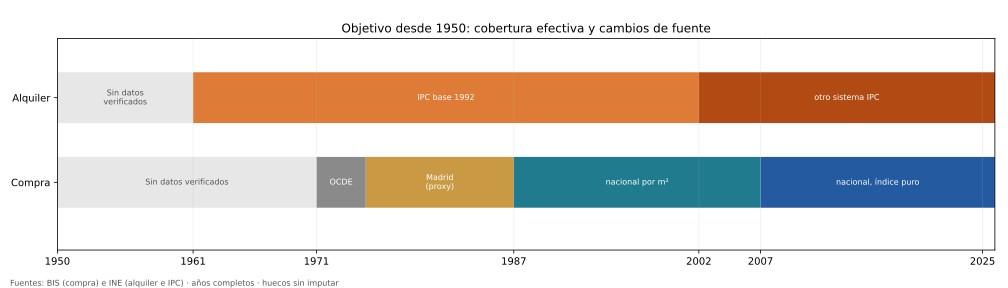

In [2]:
from spain_housing.long_history import run_long_history, compare_window
figures, findings = run_long_history(ROOT)
TABLES = ROOT / "reports/tables/since1950"
FIGURES = ROOT / "reports/figures/since1950"
coverage = pd.read_csv(TABLES / "annual_coverage_1950_2025.csv")
display(coverage.head(22))
display(SVG(filename=str(FIGURES / "01_coverage_since1950.svg")))

## 2. Compra nominal y real: BIS 1971–2025

Base común BIS **2010 = 100**, medias de cuatro trimestres completos, sin convertir a euros.
El índice real BIS está deflactado por IPC. Los paneles comparten escala; la línea discontinua
y la franja distinguen el proxy de Madrid. Hay cambios de fuente en 1975, 1987 y 2007.

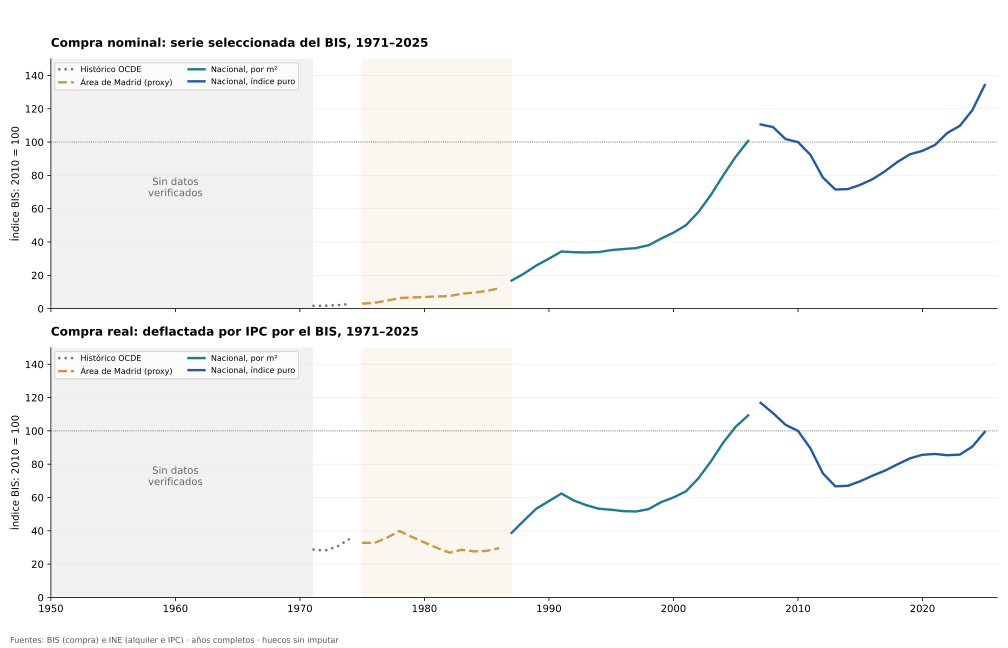

,year,value,metric,base,source_id,coverage
13,1984,9.631475,purchase_nominal,2010=100,bis_nominal.csv,Madrid_area_proxy
14,1985,10.599250,purchase_nominal,2010=100,bis_nominal.csv,Madrid_area_proxy
15,1986,12.225725,purchase_nominal,2010=100,bis_nominal.csv,Madrid_area_proxy
16,1987,16.842550,purchase_nominal,2010=100,bis_nominal.csv,national_per_m2
17,1988,21.054500,purchase_nominal,2010=100,bis_nominal.csv,national_per_m2
18,1989,25.957600,purchase_nominal,2010=100,bis_nominal.csv,national_per_m2
68,1984,27.650450,purchase_real,2010=100,bis_real.csv,Madrid_area_proxy
69,1985,27.955400,purchase_real,2010=100,bis_real.csv,Madrid_area_proxy
70,1986,29.609700,purchase_real,2010=100,bis_real.csv,Madrid_area_proxy
71,1987,38.770300,purchase_real,2010=100,bis_real.csv,national_per_m2


In [3]:
display(SVG(filename=str(FIGURES / "02_purchase_bis_nominal_real.svg")))
# Inspeccionar las observaciones y su ámbito, en lugar de asumir cobertura uniforme.
display(purchase.query('year >= 1984 and year <= 1989'))

## 3. Alquiler: tasas anuales desde 1962, con ruptura en 2002

El IPC de alquiler es distinto del IPVA fiscal del notebook 01b. Sus niveles se mantienen
con la base original de cada sistema. El siguiente cálculo procesa cada sistema por separado;
2002 queda sin variación porque no se compara automáticamente con 2001.

,nominal_pct,real_pct,segment
year,,,
1999,3.527,1.190,1961_2001
2000,3.758,0.313,1961_2001
2001,4.245,0.633,1961_2001
2002,NaN,NaN,2002_2025
2003,4.265,1.189,2002_2025
2004,4.101,1.030,2002_2025


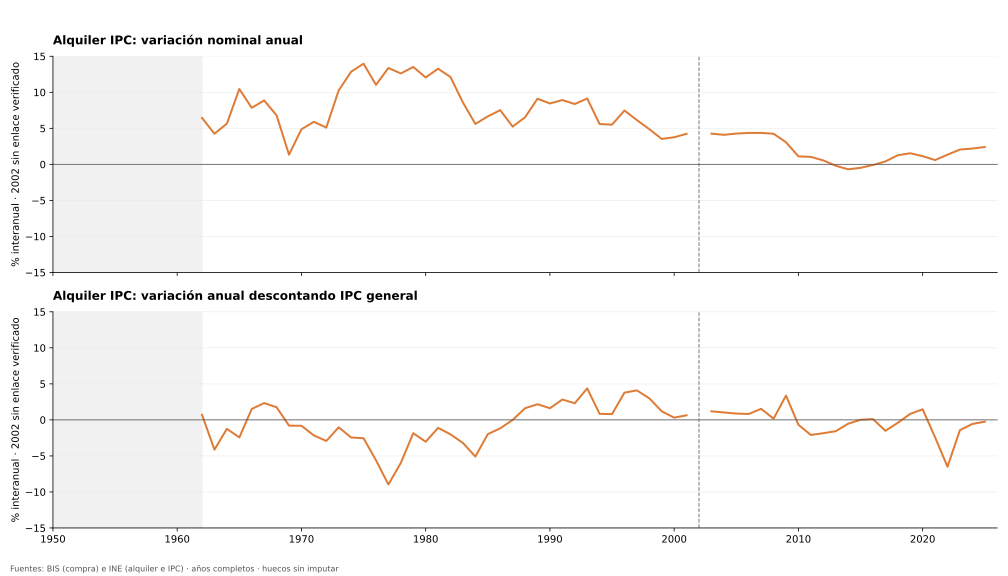

In [4]:
annual_rates = []
for segment, data in rental.groupby("segment"):
    rent = data.query('metric == "rent_cpi"').set_index("year").value.sort_index()
    cpi = data.query('metric == "cpi_general"').set_index("year").value.sort_index()
    real_rent = rent / cpi.reindex(rent.index)
    rates = pd.DataFrame({
        "nominal_pct": rent.pct_change(fill_method=None) * 100,
        "real_pct": real_rent.pct_change(fill_method=None) * 100,
    })
    rates["segment"] = segment
    annual_rates.append(rates)
annual_rates = pd.concat(annual_rates).sort_index()
display(annual_rates.loc[1999:2004].round(3))
display(SVG(filename=str(FIGURES / "03_rental_yearly_nominal_real.svg")))

## 4. Comparaciones nacionales con años, base y deflactor comunes

Se usan **1987–2001** y **2002–2025**. La primera empieza después del proxy madrileño;
la segunda comienza tras la ruptura del IPC. No se calcula un acumulado 1950–2025.
Cada par nominal/real comparte su escala. Las ventanas difieren en base y duración.

,first_year,last_year,metric,measure,change_pct
0,1987,2001,purchase,nominal,197.38
1,1987,2001,rent,nominal,142.43
2,1987,2001,purchase,real,64.15
3,1987,2001,rent,real,33.82
4,2002,2025,purchase,nominal,131.53
5,2002,2025,rent,nominal,52.49
6,2002,2025,purchase,real,39.00
7,2002,2025,rent,real,-8.45


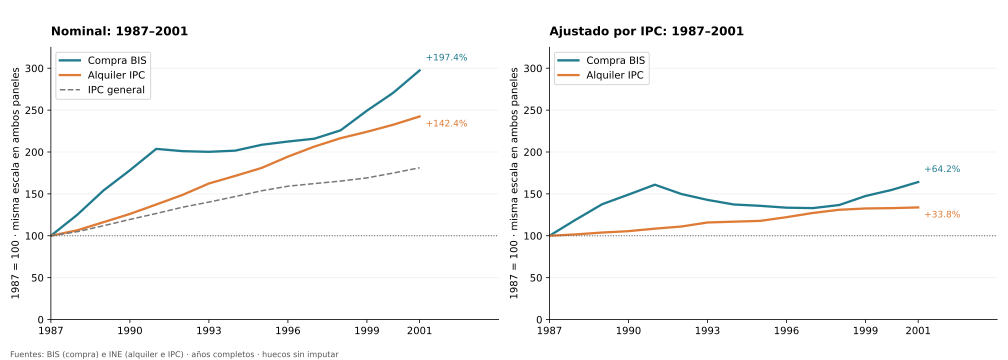

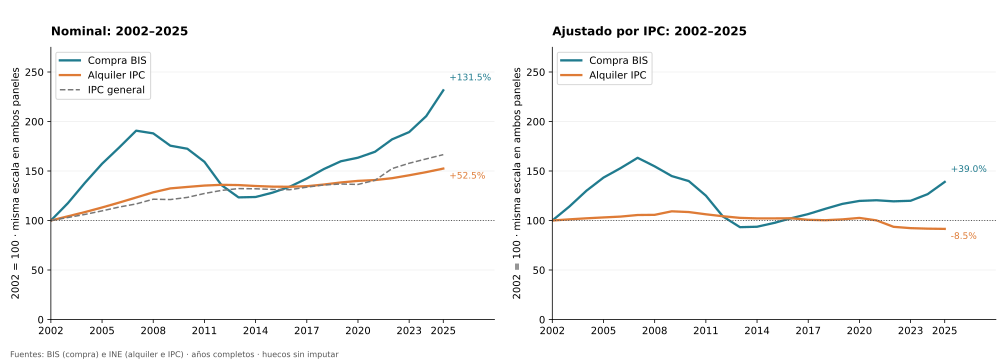

In [5]:
display(findings.round(2))
display(SVG(filename=str(FIGURES / "04_comparison_1987_2001.svg")))
display(SVG(filename=str(FIGURES / "04_comparison_2002_2025.svg")))

## 5. Cálculo visible de la comparación moderna

Se rebasan ambas series a **2002 = 100**, y se usa el mismo IPC general anual para
las dos. Los índices no representan ingresos ni el esfuerzo real de un hogar.

,Compra nominal,Alquiler nominal,IPC,Compra real,Alquiler real
2002,100.00,100.00,100.00,100.00,100.00
2011,159.31,135.32,127.30,125.14,106.29
2025,231.53,152.49,166.57,139.00,91.55


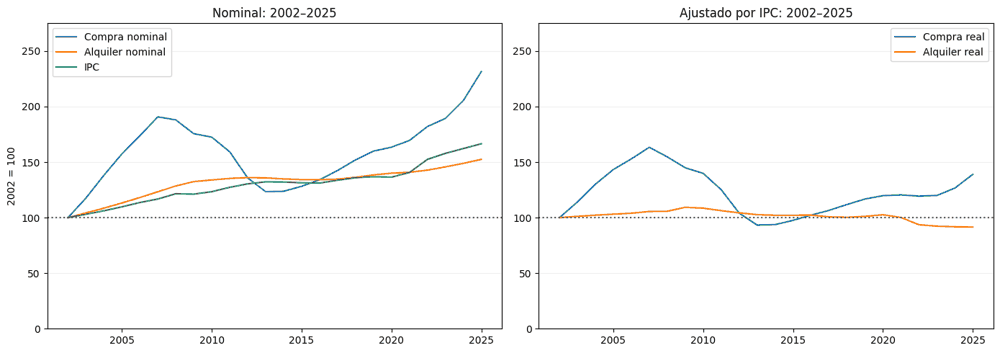

In [6]:
years = list(range(2002, 2026))
p = purchase.query('metric == "purchase_nominal"').set_index("year").value
modern = rental.query('segment == "2002_2025"')
r = modern.query('metric == "rent_cpi"').set_index("year").value
cpi = modern.query('metric == "cpi_general"').set_index("year").value
comparison = pd.DataFrame(index=years)
comparison["Compra nominal"] = p.loc[years] / p.loc[2002] * 100
comparison["Alquiler nominal"] = r.loc[years] / r.loc[2002] * 100
comparison["IPC"] = cpi.loc[years] / cpi.loc[2002] * 100
comparison["Compra real"] = comparison["Compra nominal"] / (comparison["IPC"] / 100)
comparison["Alquiler real"] = comparison["Alquiler nominal"] / (comparison["IPC"] / 100)
display(comparison.loc[[2002, 2011, 2025]].round(2))
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
comparison[["Compra nominal", "Alquiler nominal", "IPC"]].plot(ax=axes[0])
comparison[["Compra real", "Alquiler real"]].plot(ax=axes[1])
for ax, title in zip(axes, ["Nominal", "Ajustado por IPC"]):
    ax.set(title=f"{title}: 2002–2025", ylim=(0, 275), ylabel="2002 = 100")
    ax.tick_params(axis="y", labelleft=True)
    ax.axhline(100, color="#555", linestyle=":")
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
display(fig)
plt.close(fig)

## Qué falta y qué puede afirmarse

La investigación ha recuperado fuentes anteriores a las utilizadas inicialmente, pero aún no
hay precios nacionales verificados para compra 1950–1970 ni alquiler 1950–1960 en este proyecto.
Se localizó una reconstrucción académica desde 1959, pendiente de extraer y validar; no se
presentan sus estimaciones como observaciones. El enlace del alquiler entre 2001 y 2002 sigue
sin verificarse. Los vacíos no demuestran que no existan otras fuentes.

La conclusión del IPVA 2011–2024 no describe todo este horizonte. Para estudiar accesibilidad
hay que añadir ingresos y distinguir territorios y contratos. Los efectos de leyes o gobiernos
requieren un diseño específico: estas gráficas son descriptivas.

Informe: `reports/block_01_since_1950.md`. Fuentes: `data/snapshots/history1950/source_manifest.json`.